# Diabetic Retinopathy Classification — Final Reproducible Notebook

**Finalized scope:** DenseNet-121 C (primary model), DenseNet-121 B (baseline), a trained 4-qubit VQC comparison, and DenseNet explainability with Grad-CAM++ and Neuro-Symbolic AI.

This notebook fine-tunes the finalized DenseNet-121 C model (default **2 epochs** for a smoke test; change `EPOCHS` to `100` for a longer run), keeps DenseNet B as the baseline, evaluates the existing 4-qubit VQC checkpoint, adds a rule-based Neuro-Symbolic AI layer, generates **Grad-CAM++ only**, and saves report-ready outputs. It selects the best DenseNet C checkpoint using validation macro-F1 and does not use the test set for checkpoint selection.

### Final test results previously obtained

| Model | Accuracy | Macro-F1 | Weighted-F1 | QWK |
|---|---:|---:|---:|---:|
| DenseNet B | 80.13% | 61.46% | 78.08% | 0.8002 |
| DenseNet C | 78.74% | 64.60% | 78.30% | 0.8249 |
| VQC | 69.48% | 57.11% | 70.91% | 0.7692 |

DenseNet C is the primary model because it has the highest macro-F1 and QWK among these evaluated models. DenseNet B remains the accuracy baseline. The current VQC is a comparison, not the best-performing model.

**Important:** The saved test metrics above are included as reference. Running the evaluation cells below recomputes them from the saved checkpoints and prediction pipeline. Ensure the image normalization matches the training setup before treating a rerun as the definitive result.

## 1. Environment and Google Drive

Run the notebook from top to bottom in Google Colab. If your supervisor has a stronger GPU, they can run this same notebook after accessing the Drive assets listed in the configuration cell.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

%pip -q install timm pennylane scikit-learn matplotlib pandas pillow torchvision

import os, json, time, warnings
from pathlib import Path, PureWindowsPath
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import timm
import pennylane as qml
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, classification_report, confusion_matrix
)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


## 2. Final paths and asset verification

The project has two Drive folders from earlier experiments. DenseNet checkpoints and CSVs are under `DDR_work (1)`, while VQC features/checkpoint are under `DDR_work`. Cached images are expected to be extracted to the Colab runtime. This cell extracts the existing cache ZIP only if the expected image directory is missing.

In [ ]:

from pathlib import Path
import pandas as pd

# Mount Google Drive first in a previous cell, if not already mounted
# from google.colab import drive
# drive.mount('/content/drive')

# Main folder: shortcut to Shared with me / DDR_work
ROOT = Path('/content/drive/MyDrive/DDR_work')

VQC_DIR = ROOT / 'vqc_results_512'
RESULTS_DIR = ROOT / 'train_results_v2'
EDA_DIR = ROOT / 'eda_outputs'

B_CKPT = RESULTS_DIR / 'dn121_512_b_best.pt'
C_CKPT = RESULTS_DIR / 'dn121_512_c_best.pt'
TRAINED_C_CKPT = RESULTS_DIR / 'dn121_512_c_finetuned_best.pt'

TRAIN_CSV = EDA_DIR / 'ddr_train_cached.csv'
VALID_CSV = EDA_DIR / 'ddr_valid_cached.csv'
TEST_CSV = EDA_DIR / 'ddr_test_cached.csv'

VQC_CKPT = VQC_DIR / 'best_vqc.pt'
VQC_FEATURES = VQC_DIR / 'vqc_preprocessed_features.npz'

# Cache ZIP remains in DDR_work on Drive
CACHE_ZIP = ROOT / 'cache_512_clahe.zip'

# Extract images into the Colab runtime, not Google Drive
CACHE_PARENT = Path('/content/DDR_work/cache_512_clahe')
CACHE_DIR = CACHE_PARENT / 'cache_512_clahe'

OUT_DIR = RESULTS_DIR / 'final_model_package_outputs'
OUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']
NUM_CLASSES = 5

# Extract the image cache if needed
if not CACHE_DIR.exists() and CACHE_ZIP.exists():
    import zipfile

    CACHE_PARENT.mkdir(parents=True, exist_ok=True)
    print('Extracting cached images to runtime (not to Drive)...')

    with zipfile.ZipFile(CACHE_ZIP) as zf:
        zf.extractall(CACHE_PARENT)

# Verify required files
required = [
    B_CKPT, C_CKPT,
    TRAIN_CSV, VALID_CSV, TEST_CSV,
    VQC_CKPT, VQC_FEATURES
]

missing = [str(p) for p in required if not p.exists()]

for p in required:
    print(('FOUND  ' if p.exists() else 'MISSING'), p)

if missing:
    raise FileNotFoundError(
        'Missing required artifacts: ' + '; '.join(missing)
    )

if not CACHE_DIR.exists():
    raise FileNotFoundError(
        f'Cached image directory not found: {CACHE_DIR}. '
        'Check the ZIP location and extracted folder structure.'
    )

# Verify CSV files
for split, csv_path in [
    ('train', TRAIN_CSV),
    ('valid', VALID_CSV),
    ('test', TEST_CSV)
]:
    frame = pd.read_csv(csv_path)
    print(f'{split}: {len(frame)} rows; columns={list(frame.columns)}')

print('Cache directory:', CACHE_DIR)
print('Outputs will be saved to:', OUT_DIR)


FOUND   /content/drive/MyDrive/DDR_work/train_results_v2/dn121_512_b_best.pt
FOUND   /content/drive/MyDrive/DDR_work/train_results_v2/dn121_512_c_best.pt
FOUND   /content/drive/MyDrive/DDR_work/eda_outputs/ddr_train_cached.csv
FOUND   /content/drive/MyDrive/DDR_work/eda_outputs/ddr_valid_cached.csv
FOUND   /content/drive/MyDrive/DDR_work/eda_outputs/ddr_test_cached.csv
FOUND   /content/drive/MyDrive/DDR_work/vqc_results_512/best_vqc.pt
FOUND   /content/drive/MyDrive/DDR_work/vqc_results_512/vqc_preprocessed_features.npz
train: 6210 rows; columns=['split', 'image', 'label', 'path', 'w', 'h', 'md5', 'cpath']
valid: 2487 rows; columns=['split', 'image', 'label', 'path', 'w', 'h', 'md5', 'cpath']
test: 3725 rows; columns=['split', 'image', 'label', 'path', 'w', 'h', 'md5', 'cpath']
Cache directory: /content/DDR_work/cache_512_clahe/cache_512_clahe
Outputs will be saved to: /content/drive/MyDrive/DDR_work/train_results_v2/final_model_package_outputs


## 4. Load test images and evaluate DenseNet B/C

This uses deterministic preprocessing (tensor conversion and ImageNet normalization), consistent with the configuration used in the prior evaluations. If the original training notebook used different normalization, correct this transform before interpreting metrics.

In [ ]:
IMAGE_SIZE = 512
BATCH_SIZE = 32
NUM_WORKERS = 2

test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


def resolve_image_path(row):
    filename = str(row['image']) if 'image' in row.index else PureWindowsPath(str(row['cpath'])).name
    split = str(row['split']) if 'split' in row.index else 'test'
    candidate = CACHE_DIR / split / filename
    if candidate.is_file():
        return candidate
    matches = list(CACHE_DIR.rglob(filename))
    if matches:
        return matches[0]
    raise FileNotFoundError(f'Cannot locate cached image {filename}; checked {candidate}')

class DDRImageDataset(Dataset):
    def __init__(self, csv_path, transform):
        self.df = pd.read_csv(csv_path).reset_index(drop=True)
        self.transform = transform
        self.paths = [resolve_image_path(row) for _, row in self.df.iterrows()]
        self.labels = self.df['label'].astype(int).to_numpy()
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as im:
            image = im.convert('RGB')
        return self.transform(image), int(self.labels[idx]), idx

test_ds = DDRImageDataset(TEST_CSV, test_transform)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS,
                         pin_memory=(DEVICE.type == 'cuda'))
y_test = test_ds.labels
print('Test images:', len(test_ds))
print('Test class counts:', dict(zip(*np.unique(y_test, return_counts=True))))


def load_state_dict(path):
    ckpt = torch.load(path, map_location='cpu', weights_only=False)
    if isinstance(ckpt, dict) and 'model_state_dict' in ckpt:
        ckpt = ckpt['model_state_dict']
    elif isinstance(ckpt, dict) and 'state_dict' in ckpt:
        ckpt = ckpt['state_dict']
    return {k.removeprefix('module.'): v for k, v in ckpt.items()}


def build_densenet(path):
    net = timm.create_model('densenet121', pretrained=False,
                            num_classes=NUM_CLASSES, drop_rate=0.3)
    net.load_state_dict(load_state_dict(path), strict=True)
    return net.to(DEVICE).eval()


def evaluate_image_model(net, loader):
    preds, probs = [], []
    with torch.inference_mode():
        for xb, _, _ in loader:
            xb = xb.to(DEVICE, non_blocking=True)
            logits = net(xb)
            probs.append(torch.softmax(logits, dim=1).cpu().numpy())
            preds.extend(logits.argmax(1).cpu().numpy().tolist())
    return np.asarray(preds, dtype=np.int64), np.concatenate(probs, axis=0)

# Evaluate the newly fine-tuned checkpoint. Fall back to the finalized C checkpoint only if needed.
EFFECTIVE_C_CKPT = TRAINED_C_CKPT if TRAINED_C_CKPT.exists() else C_CKPT
print('DenseNet C checkpoint used for final evaluation:', EFFECTIVE_C_CKPT)
models = {
    'DenseNet B': build_densenet(B_CKPT),
    'DenseNet C': build_densenet(EFFECTIVE_C_CKPT),
}
predictions = {}
probabilities = {}
for name, net in models.items():
    print('Evaluating', name)
    predictions[name], probabilities[name] = evaluate_image_model(net, test_loader)

Test images: 3725
Test class counts: {np.int64(0): np.int64(1846), np.int64(1): np.int64(189), np.int64(2): np.int64(1344), np.int64(3): np.int64(71), np.int64(4): np.int64(275)}
DenseNet C checkpoint used for final evaluation: /content/drive/MyDrive/DDR_work/train_results_v2/dn121_512_c_finetuned_best.pt
Evaluating DenseNet B
Evaluating DenseNet C


## 3. Fine-tune the finalized primary model (DenseNet-121 C)

**Training is included.** The notebook starts from the existing DenseNet C checkpoint and fine-tunes it using the training split, selecting the best checkpoint by **validation macro-F1**. The default is deliberately `EPOCHS = 2` for a smoke test. Once the run completes without errors, your ma'am can change it to `100` (or another value). The held-out test set is not used for training or checkpoint selection.

The fine-tuned checkpoint is saved separately as `dn121_512_c_finetuned_best.pt`; the original finalized checkpoint is not overwritten. If training is interrupted, rerun this cell. For longer runs, consider early stopping and monitor validation macro-F1. More epochs do not guarantee higher accuracy and can overfit, especially with imbalanced classes.


In [ ]:

# Training settings with early stopping
EPOCHS = 100
PATIENCE = 99
MIN_DELTA = 0.001

LEARNING_RATE = 1e-5
TRAIN_BATCH_SIZE = 16  # lower to 4 if GPU memory runs out
TRAIN_NUM_WORKERS = 2

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])
valid_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

train_ds = DDRImageDataset(TRAIN_CSV, train_transform)
valid_ds = DDRImageDataset(VALID_CSV, valid_transform)
train_loader = DataLoader(
    train_ds, batch_size=TRAIN_BATCH_SIZE, shuffle=True,
    num_workers=TRAIN_NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda')
)
valid_loader = DataLoader(
    valid_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda')
)

# Start from the already selected DenseNet C checkpoint; keep the original file untouched.
train_model = timm.create_model('densenet121', pretrained=False,
                                num_classes=NUM_CLASSES, drop_rate=0.3)
train_model.load_state_dict(load_state_dict(C_CKPT), strict=True)
train_model = train_model.to(DEVICE)

# Mild inverse-square-root class weighting helps avoid completely ignoring rare grades.
class_counts = np.bincount(train_ds.labels, minlength=NUM_CLASSES).astype(np.float32)
class_weights = 1.0 / np.sqrt(np.maximum(class_counts, 1.0))
class_weights = class_weights / class_weights.mean()
criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
)
optimizer = torch.optim.AdamW(
    train_model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4
)
use_amp = DEVICE.type == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

best_val_macro_f1 = -1.0
epochs_without_improvement = 0
training_history = []

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()
    train_model.train()
    running_loss, train_seen = 0.0, 0

    for xb, yb, _ in train_loader:
        xb = xb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
            logits = train_model(xb)
            loss = criterion(logits, yb)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += float(loss.detach()) * len(yb)
        train_seen += len(yb)

    train_model.eval()
    val_true, val_pred = [], []

    with torch.inference_mode():
        for xb, yb, _ in valid_loader:
            xb = xb.to(DEVICE, non_blocking=True)

            with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
                logits = train_model(xb)

            val_pred.extend(logits.argmax(1).cpu().numpy().tolist())
            val_true.extend(yb.numpy().tolist())

    val_macro_f1 = f1_score(
        val_true, val_pred, average='macro', zero_division=0
    )
    val_accuracy = accuracy_score(val_true, val_pred)

    epoch_row = {
        'epoch': epoch,
        'train_loss': running_loss / max(train_seen, 1),
        'validation_accuracy': val_accuracy,
        'validation_macro_f1': val_macro_f1,
        'seconds': time.time() - epoch_start
    }
    training_history.append(epoch_row)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"train loss {epoch_row['train_loss']:.4f} | "
        f"val acc {val_accuracy:.4f} | "
        f"val macro-F1 {val_macro_f1:.4f} | "
        f"{epoch_row['seconds']:.1f}s"
    )

    # Save the best checkpoint and track early stopping patience.
    if val_macro_f1 > best_val_macro_f1 + MIN_DELTA:
        best_val_macro_f1 = val_macro_f1
        epochs_without_improvement = 0

        torch.save(train_model.state_dict(), TRAINED_C_CKPT)
        print('  Saved new best validation checkpoint:', TRAINED_C_CKPT)

    else:
        epochs_without_improvement += 1
        print(
            f'  No significant improvement: '
            f'{epochs_without_improvement}/{PATIENCE} epochs'
        )

    if epochs_without_improvement >= PATIENCE:
        print(
            f'Early stopping triggered at epoch {epoch}. '
            f'Best validation Macro-F1: {best_val_macro_f1:.4f}'
        )
        break

pd.DataFrame(training_history).to_csv(
    OUT_DIR / 'densenet_c_finetuning_history.csv', index=False
)

print('Training history saved to:', OUT_DIR / 'densenet_c_finetuning_history.csv')
print('Best checkpoint:', TRAINED_C_CKPT)
print('Best validation macro-F1:', round(best_val_macro_f1, 4))



Epoch 1/100 | train loss 0.2747 | val acc 0.8476 | val macro-F1 0.6798 | 173.0s
  Saved new best validation checkpoint: /content/drive/MyDrive/DDR_work/train_results_v2/dn121_512_c_finetuned_best.pt
Epoch 2/100 | train loss 0.2585 | val acc 0.8605 | val macro-F1 0.6780 | 163.7s
  No significant improvement: 1/99 epochs
Epoch 3/100 | train loss 0.2356 | val acc 0.8492 | val macro-F1 0.6768 | 167.5s
  No significant improvement: 2/99 epochs
Epoch 4/100 | train loss 0.2153 | val acc 0.8625 | val macro-F1 0.6912 | 164.6s
  Saved new best validation checkpoint: /content/drive/MyDrive/DDR_work/train_results_v2/dn121_512_c_finetuned_best.pt
Epoch 5/100 | train loss 0.2013 | val acc 0.8629 | val macro-F1 0.6801 | 164.8s
  No significant improvement: 1/99 epochs
Epoch 6/100 | train loss 0.1766 | val acc 0.8569 | val macro-F1 0.6625 | 164.0s
  No significant improvement: 2/99 epochs
Epoch 7/100 | train loss 0.1712 | val acc 0.8637 | val macro-F1 0.6855 | 163.7s
  No significant improvement: 3/99

In [ ]:
# Reload the best fine-tuned weights and refresh DenseNet C test predictions before final reporting.
models['DenseNet C'] = build_densenet(TRAINED_C_CKPT)
predictions['DenseNet C'], probabilities['DenseNet C'] = evaluate_image_model(
    models['DenseNet C'], test_loader
)
print('Refreshed DenseNet C test predictions from the best fine-tuned checkpoint.')


Refreshed DenseNet C test predictions from the best fine-tuned checkpoint.


## 5. Evaluate the saved VQC checkpoint

The VQC uses the already-saved four-dimensional preprocessed features. It is evaluated as its own model; Grad-CAM is not applied to the VQC because it does not process the original image pixels directly.

In [ ]:
vqc_ckpt = torch.load(VQC_CKPT, map_location='cpu', weights_only=False)
vqc_data = np.load(VQC_FEATURES, allow_pickle=False)
X_test_vqc = vqc_data['X_test'].astype(np.float32)
y_test_vqc = vqc_data['y_test'].astype(np.int64)
assert np.array_equal(y_test_vqc, y_test), (
    'VQC saved test labels do not match test CSV order. Do not evaluate until aligned by image identity.'
)

n_qubits = int(vqc_ckpt['n_qubits'])
n_layers = int(vqc_ckpt['n_layers'])
vqc_device = qml.device('default.qubit', wires=n_qubits)

@qml.qnode(vqc_device, interface='torch', diff_method='backprop')
def quantum_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(n_qubits), rotation='Y')
    qml.StronglyEntanglingLayers(weights, wires=range(n_qubits))
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

class VQCClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.quantum = qml.qnn.TorchLayer(
            quantum_circuit, {'weights': (n_layers, n_qubits, 3)}
        )
        self.classifier = nn.Linear(n_qubits, NUM_CLASSES)
    def forward(self, x):
        return self.classifier(self.quantum(x))

vqc_model = VQCClassifier()
vqc_model.load_state_dict(vqc_ckpt['model_state_dict'], strict=True)
vqc_model.eval()
vqc_pred, vqc_prob_list = [], []
with torch.inference_mode():
    for start in range(0, len(X_test_vqc), 32):
        xb = torch.from_numpy(X_test_vqc[start:start+32])
        logits = vqc_model(xb)
        vqc_pred.extend(logits.argmax(1).numpy().tolist())
        vqc_prob_list.append(torch.softmax(logits, dim=1).numpy())

predictions['VQC'] = np.asarray(vqc_pred, dtype=np.int64)
probabilities['VQC'] = np.concatenate(vqc_prob_list, axis=0)
print('VQC test features:', X_test_vqc.shape)

VQC test features: (3725, 4)


## 6. Final metrics, reports, and confusion matrices

This creates the comparison CSVs and per-model confusion-matrix figures. These are evaluation outputs only; do not use them to tune the models.

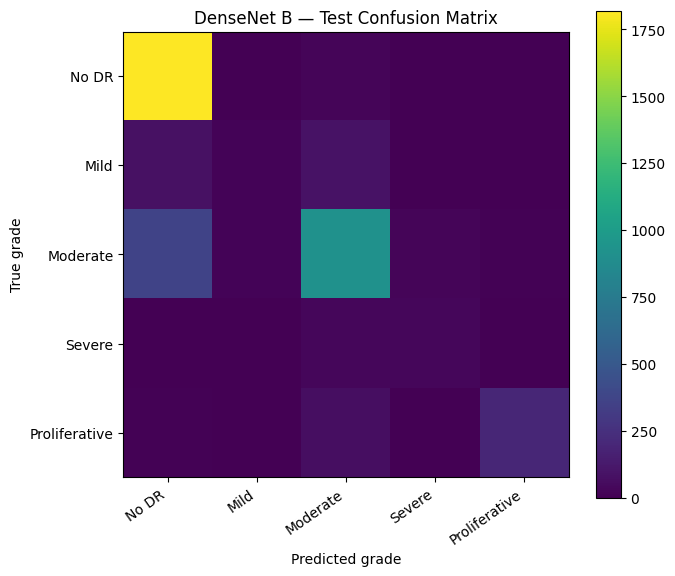


DenseNet B classification report
               precision    recall  f1-score   support

        No DR     0.7964    0.9854    0.8809      1846
         Mild     0.4545    0.0794    0.1351       189
     Moderate     0.8118    0.6868    0.7441      1344
       Severe     0.5484    0.4789    0.5113        71
Proliferative     0.9282    0.7055    0.8017       275

     accuracy                         0.8013      3725
    macro avg     0.7079    0.5872    0.6146      3725
 weighted avg     0.7896    0.8013    0.7808      3725



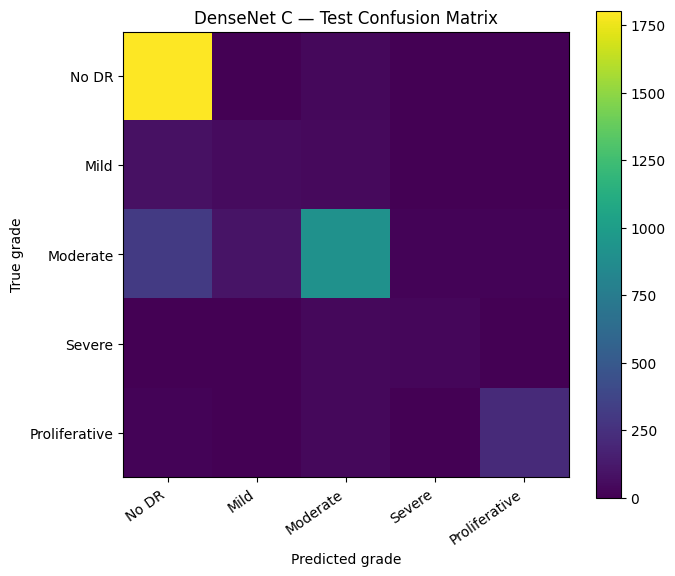


DenseNet C classification report
               precision    recall  f1-score   support

        No DR     0.8176    0.9762    0.8899      1846
         Mild     0.3590    0.2963    0.3246       189
     Moderate     0.8455    0.6801    0.7538      1344
       Severe     0.6042    0.4085    0.4874        71
Proliferative     0.9025    0.7745    0.8337       275

     accuracy                         0.8091      3725
    macro avg     0.7058    0.6271    0.6579      3725
 weighted avg     0.8066    0.8091    0.8003      3725



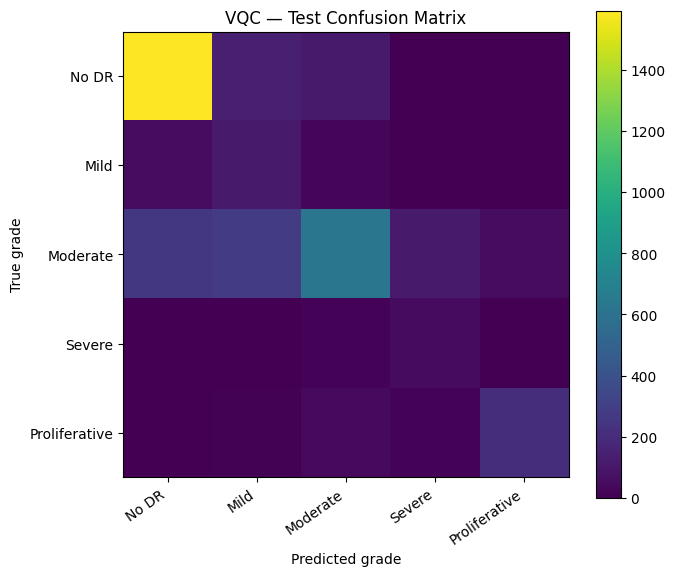


VQC classification report
               precision    recall  f1-score   support

        No DR     0.8349    0.8629    0.8487      1846
         Mild     0.2073    0.6032    0.3085       189
     Moderate     0.7703    0.4665    0.5811      1344
       Severe     0.2458    0.6197    0.3520        71
Proliferative     0.7664    0.7636    0.7650       275

     accuracy                         0.6948      3725
    macro avg     0.5649    0.6632    0.5711      3725
 weighted avg     0.7635    0.6948    0.7091      3725


OVERALL TEST COMPARISON
     Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1    QWK
DenseNet B    0.8013           0.7079        0.5872    0.6146       0.7808 0.8002
DenseNet C    0.8091           0.7058        0.6271    0.6579       0.8003 0.8129
       VQC    0.6948           0.5649        0.6632    0.5711       0.7091 0.7692

CLASS-WISE F1
Model          DenseNet B  DenseNet C     VQC
Grade                                        
Mild           

In [ ]:
summary_rows = []
classwise_rows = []

for name, pred in predictions.items():
    summary_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Macro Precision': precision_score(y_test, pred, average='macro', zero_division=0),
        'Macro Recall': recall_score(y_test, pred, average='macro', zero_division=0),
        'Macro F1': f1_score(y_test, pred, average='macro', zero_division=0),
        'Weighted F1': f1_score(y_test, pred, average='weighted', zero_division=0),
        'QWK': cohen_kappa_score(y_test, pred, weights='quadratic')
    })
    report = classification_report(y_test, pred, labels=list(range(NUM_CLASSES)),
                                   target_names=CLASS_NAMES, output_dict=True,
                                   zero_division=0)
    for grade in CLASS_NAMES:
        classwise_rows.append({'Model': name, 'Grade': grade,
                               'Precision': report[grade]['precision'],
                               'Recall': report[grade]['recall'],
                               'F1-score': report[grade]['f1-score'],
                               'Support': int(report[grade]['support'])})
    cm = confusion_matrix(y_test, pred, labels=list(range(NUM_CLASSES)))
    safe = name.lower().replace(' ', '_')
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(OUT_DIR / f'{safe}_confusion_matrix.csv')
    pd.DataFrame({'actual_grade': y_test, 'predicted_grade': pred}).to_csv(OUT_DIR / f'{safe}_predictions.csv', index=False)
    plt.figure(figsize=(7, 6))
    plt.imshow(cm, interpolation='nearest')
    plt.title(f'{name} — Test Confusion Matrix')
    plt.colorbar()
    plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=35, ha='right')
    plt.yticks(range(NUM_CLASSES), CLASS_NAMES)
    plt.xlabel('Predicted grade')
    plt.ylabel('True grade')
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'{safe}_confusion_matrix.png', dpi=180)
    plt.show()
    plt.close()
    print(f'\n{name} classification report')
    print(classification_report(y_test, pred, labels=list(range(NUM_CLASSES)),
                                target_names=CLASS_NAMES, digits=4, zero_division=0))

summary_df = pd.DataFrame(summary_rows)
classwise_df = pd.DataFrame(classwise_rows)
summary_df.to_csv(OUT_DIR / 'final_test_model_comparison.csv', index=False)
classwise_df.to_csv(OUT_DIR / 'final_test_classwise_comparison.csv', index=False)
print('\nOVERALL TEST COMPARISON')
print(summary_df.round(4).to_string(index=False))
print('\nCLASS-WISE F1')
print(classwise_df.pivot(index='Grade', columns='Model', values='F1-score').round(4).to_string())

## 7. Neuro-Symbolic AI: probability-based rules and human-review recommendations

This layer combines neural model probabilities with transparent, human-defined rules. It is a lightweight rule-based neuro-symbolic component: it does not retrain the neural model, and its thresholds should be validated with domain experts before any clinical use. The rules are applied to DenseNet C test probabilities and reported separately from classification metrics.


In [ ]:
# Neuro-symbolic reasoning uses DenseNet C's probability distribution plus explicit rules.
# These thresholds are configurable examples, not clinically validated cut-offs.
NS_MIN_CONFIDENCE = 0.55
NS_MIN_ADJACENT_MASS = 0.70
NS_MAX_ENTROPY = 1.25

def neuro_symbolic_reason(prob_row):
    p = np.asarray(prob_row, dtype=np.float64)
    p = p / (p.sum() + 1e-12)
    pred = int(np.argmax(p))
    confidence = float(p[pred])
    entropy = float(-(p * np.log(p + 1e-12)).sum())
    lo, hi = max(0, pred - 1), min(NUM_CLASSES, pred + 2)
    adjacent_mass = float(p[lo:hi].sum())
    rules = []
    if confidence < NS_MIN_CONFIDENCE:
        rules.append('LOW_CONFIDENCE: confidence below configured threshold')
    if adjacent_mass < NS_MIN_ADJACENT_MASS:
        rules.append('GRADE_INCONSISTENCY: probability mass is spread beyond adjacent grades')
    if entropy > NS_MAX_ENTROPY:
        rules.append('HIGH_UNCERTAINTY: probability distribution has high entropy')
    if not rules:
        rules.append('NO_REVIEW_RULE_TRIGGERED: configured rules did not flag this prediction')
    return {
        'predicted_grade_id': pred,
        'predicted_grade': CLASS_NAMES[pred],
        'confidence': confidence,
        'entropy': entropy,
        'adjacent_grade_probability_mass': adjacent_mass,
        'rules_triggered': ' | '.join(rules),
        'manual_review_recommended': any(r.startswith(('LOW_CONFIDENCE', 'GRADE_INCONSISTENCY', 'HIGH_UNCERTAINTY')) for r in rules)
    }

ns_rows = []
for i, prob_row in enumerate(probabilities['DenseNet C']):
    row = neuro_symbolic_reason(prob_row)
    row['test_index'] = i
    row['true_grade'] = CLASS_NAMES[int(y_test[i])]
    row['correct_prediction'] = (row['predicted_grade_id'] == int(y_test[i]))
    ns_rows.append(row)
ns_df = pd.DataFrame(ns_rows)
ns_path = OUT_DIR / 'neuro_symbolic_test_predictions.csv'
ns_df.to_csv(ns_path, index=False)
print('Neuro-symbolic rule summary:')
print(ns_df['manual_review_recommended'].value_counts(dropna=False).rename(index={True: 'Manual review recommended', False: 'No configured rule triggered'}))
print('Saved:', ns_path)
display(ns_df.head(10))


Neuro-symbolic rule summary:
manual_review_recommended
No configured rule triggered    3628
Manual review recommended         97
Name: count, dtype: int64
Saved: /content/drive/MyDrive/DDR_work/train_results_v2/final_model_package_outputs/neuro_symbolic_test_predictions.csv


,predicted_grade_id,predicted_grade,confidence,entropy,adjacent_grade_probability_mass,rules_triggered,manual_review_recommended,test_index,true_grade,correct_prediction
0,0,No DR,0.999680,3.057098e-03,0.999736,NO_REVIEW_RULE_TRIGGERED: configured rules did...,False,0,No DR,True
1,0,No DR,0.999967,3.873658e-04,0.999996,NO_REVIEW_RULE_TRIGGERED: configured rules did...,False,1,No DR,True
2,4,Proliferative,1.000000,3.564383e-10,1.000000,NO_REVIEW_RULE_TRIGGERED: configured rules did...,False,2,Proliferative,True
3,1,Mild,0.595866,7.720979e-01,0.999976,NO_REVIEW_RULE_TRIGGERED: configured rules did...,False,3,Moderate,False
4,2,Moderate,0.612436,7.709344e-01,0.973540,NO_REVIEW_RULE_TRIGGERED: configured rules did...,False,4,Moderate,True
5,0,No DR,0.998928,9.196992e-03,0.999439,NO_REVIEW_RULE_TRIGGERED: configured rules did...,False,5,No DR,True
6,2,Moderate,0.956779,1.792437e-01,0.956896,NO_REVIEW_RULE_TRIGGERED: configured rules did...,False,6,Mild,False
7,0,No DR,0.998368,1.325368e-02,0.998872,NO_REVIEW_RULE_TRIGGERED: configured rules did...,False,7,No DR,True
8,0,No DR,0.999894,1.108151e-03,0.999991,NO_REVIEW_RULE_TRIGGERED: configured rules did...,False,8,No DR,True
9,2,Moderate,0.999893,1.097676e-03,0.999894,NO_REVIEW_RULE_TRIGGERED: configured rules did...,False,9,Moderate,True


## 7. Grad-CAM++ explainability for the primary DenseNet C

This section generates **Grad-CAM++ only** (not standard Grad-CAM). It creates one explanation for the first test example in each available true grade. The heatmap is a post-hoc visual explanation and is not a clinical diagnosis.


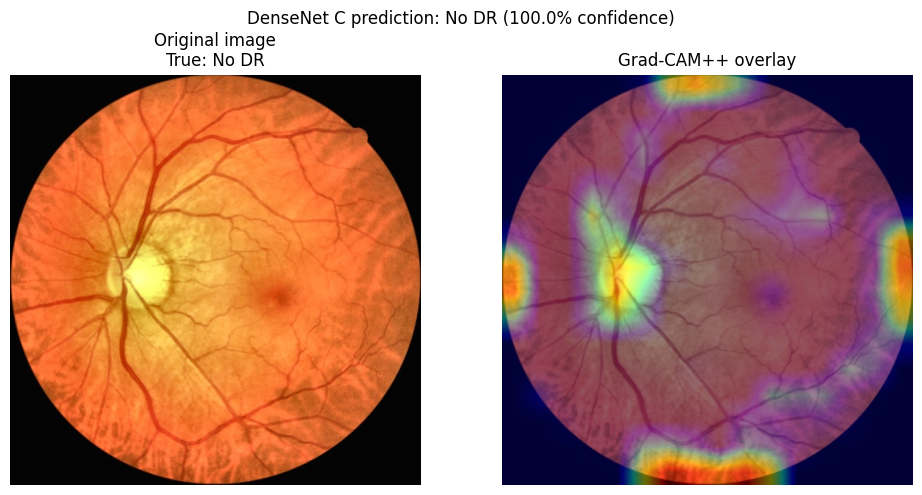

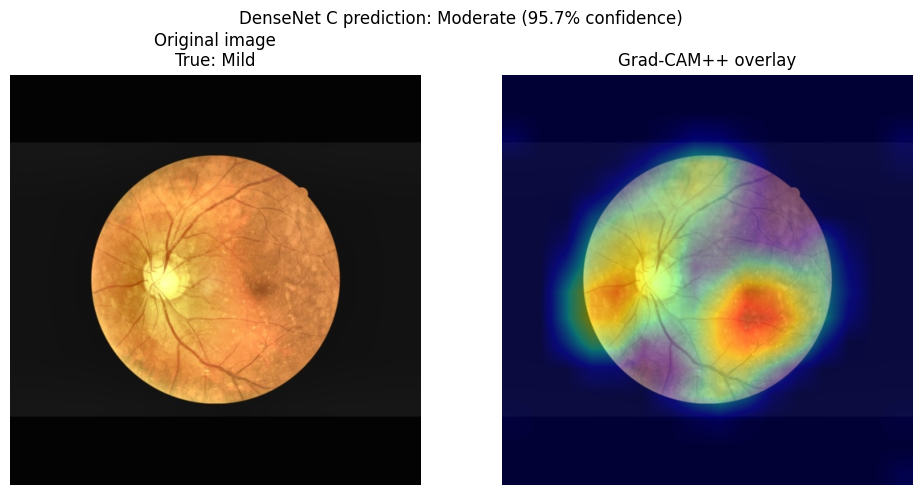

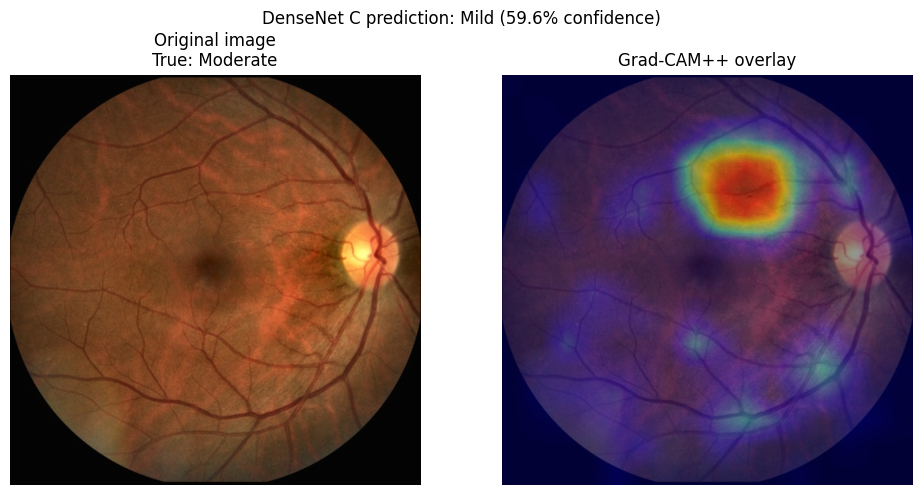

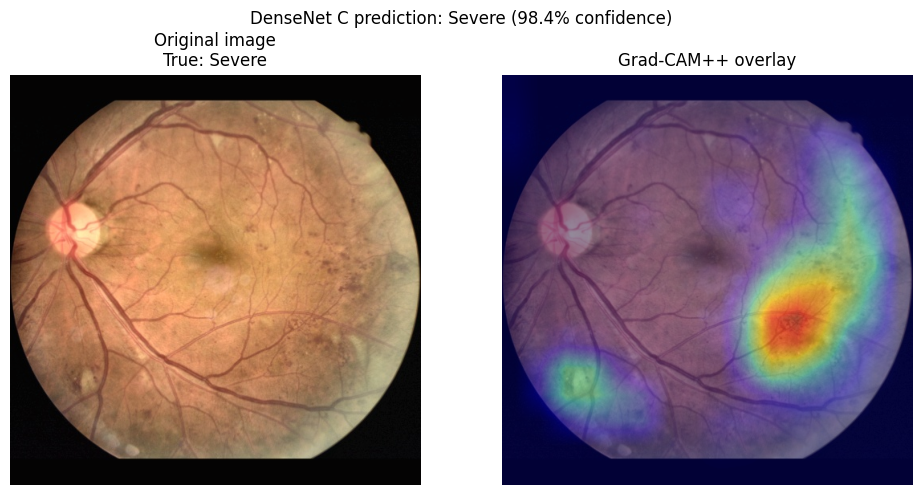

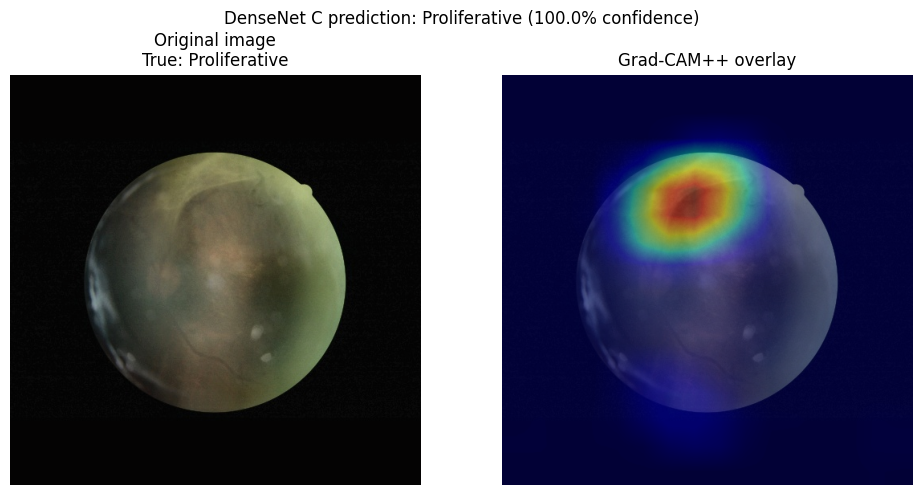

Grad-CAM++ examples saved to: /content/drive/MyDrive/DDR_work/train_results_v2/final_model_package_outputs


In [ ]:
# Grad-CAM++ only — no standard Grad-CAM is computed or displayed.
cam_model = models['DenseNet C']
target_layer = cam_model.features.denseblock4
_cam_store = {}

def _forward_hook(module, inputs, output):
    _cam_store['activations'] = output
    output.register_hook(lambda grad: _cam_store.__setitem__('gradients', grad))

hook_handle = target_layer.register_forward_hook(_forward_hook)

def make_gradcam_pp(input_tensor, class_idx):
    """Compute a Grad-CAM++-style heatmap for one normalized image [1,C,H,W]."""
    cam_model.zero_grad(set_to_none=True)
    _cam_store.clear()
    logits = cam_model(input_tensor.to(DEVICE))
    logits[0, int(class_idx)].backward()
    A = _cam_store['activations'][0]  # [channels, h, w]
    G = _cam_store['gradients'][0]
    G2, G3 = G.pow(2), G.pow(3)
    denom = 2.0 * G2 + (A * G3).sum(dim=(1, 2), keepdim=True)
    alpha = G2 / (denom + 1e-8)
    weights = (alpha * torch.relu(G)).sum(dim=(1, 2), keepdim=True)
    cam = torch.relu((weights * A).sum(dim=0))
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)
    cam = torch.nn.functional.interpolate(
        cam[None, None], size=(IMAGE_SIZE, IMAGE_SIZE),
        mode='bilinear', align_corners=False
    )[0, 0]
    return cam.detach().cpu().numpy(), logits.detach()

def denormalize_image(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    x = tensor.cpu() * std + mean
    return np.clip(x.permute(1, 2, 0).numpy(), 0, 1)

def save_gradcam_pp_panel(dataset_index, true_label):
    x, _, _ = test_ds[dataset_index]
    input_tensor = x.unsqueeze(0)
    cam_model.eval()
    with torch.enable_grad():
        heatmap, logits = make_gradcam_pp(input_tensor, int(torch.argmax(cam_model(input_tensor.to(DEVICE)), dim=1).item()))
    probs = torch.softmax(logits, dim=1)[0]
    pred = int(probs.argmax().item())
    conf = float(probs[pred].item())
    original = denormalize_image(x)
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(original)
    axes[0].set_title(f'Original image\nTrue: {CLASS_NAMES[true_label]}')
    axes[1].imshow(original)
    axes[1].imshow(heatmap, cmap='jet', alpha=0.42, vmin=0, vmax=1)
    axes[1].set_title('Grad-CAM++ overlay')
    for ax in axes:
        ax.axis('off')
    fig.suptitle(f'DenseNet C prediction: {CLASS_NAMES[pred]} ({conf:.1%} confidence)')
    fig.tight_layout()
    safe = CLASS_NAMES[true_label].lower().replace(' ', '_')
    out_path = OUT_DIR / f'gradcampp_true_{safe}_idx_{dataset_index}.png'
    fig.savefig(out_path, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return {'test_index': dataset_index, 'true_grade': CLASS_NAMES[true_label],
            'predicted_grade': CLASS_NAMES[pred], 'confidence': conf,
            'gradcam_plus_plus_file': str(out_path)}

cam_rows = []
for grade in range(NUM_CLASSES):
    indices = np.flatnonzero(y_test == grade)
    if len(indices):
        cam_rows.append(save_gradcam_pp_panel(int(indices[0]), grade))

hook_handle.remove()
pd.DataFrame(cam_rows).to_csv(OUT_DIR / 'gradcam_plus_plus_examples_index.csv', index=False)
print('Grad-CAM++ examples saved to:', OUT_DIR)
